# **EDA-Reflection-Project**
This is the Exploratory Data Analysis Project I created after learning EDA, for reflection and application of the skills I have acquire.
- What question to ask when exploring data
- Which variables to choose from to observe the relationship among them
- Which function to use to observe the relationship
- What insight CAN be concluded from the plots and charts

## **DATA DESCRIPTION:**

The Hotel Booking Demand dataset contains 119,390 booking records across 32 variables for two hotels in Portugal (one city hotel and one resort hotel) between July 2015 and August 2017. It is widely used for data analysis and machine learning tasks, such as predicting booking cancellations, customer behavior, and average daily rates.


### **PART A: DATA PREPROCESSING**

In [39]:
#Import data
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df_org=pd.read_csv(r"C:\Users\Lenovo\Desktop\CODING\EDA Reflection Projects _ Main Work\hotel_bookings.csv")
df_org.head(50)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,1/7/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,1/7/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2/7/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2/7/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,3/7/2015
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,3/7/2015
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.00,0,0,Check-Out,3/7/2015
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.00,0,1,Check-Out,3/7/2015
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.00,0,1,Canceled,6/5/2015
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.50,0,0,Canceled,22-04-15


In [45]:
df_org.query("customer_type=='Group'")

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
539,Resort Hotel,0,0,2015,July,30,19,1,0,2,...,No Deposit,240.0,NaN,0,Group,98.0,1,0,Check-Out,20-07-15
541,Resort Hotel,0,0,2015,July,30,19,1,0,2,...,No Deposit,NaN,240.0,0,Group,88.2,0,0,Check-Out,20-07-15
1156,Resort Hotel,0,0,2015,August,34,16,1,0,2,...,No Deposit,240.0,NaN,0,Group,195.0,0,0,Check-Out,17-08-15
1539,Resort Hotel,1,304,2015,September,36,3,0,3,40,...,No Deposit,NaN,NaN,0,Group,0.0,0,0,Canceled,2/1/2015
1587,Resort Hotel,1,333,2015,September,36,5,2,5,26,...,No Deposit,96.0,NaN,0,Group,0.0,0,0,Canceled,2/1/2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116048,City Hotel,0,468,2017,July,30,29,2,1,1,...,No Deposit,229.0,NaN,0,Group,0.0,0,0,Check-Out,1/8/2017
116809,City Hotel,0,76,2017,August,32,6,2,0,3,...,No Deposit,14.0,NaN,0,Group,179.5,0,1,Check-Out,8/8/2017
118165,City Hotel,0,3,2017,August,32,6,4,6,2,...,No Deposit,20.0,NaN,0,Group,89.0,0,0,Check-Out,16-08-17
118581,City Hotel,0,11,2017,August,34,25,0,2,2,...,No Deposit,98.0,NaN,0,Group,125.0,0,0,Check-Out,27-08-17


In [36]:
#Check for group booking by adult number and children number of customers
df_org["adults"].value_counts()

adults
2     89680
1     23027
3      6202
0       403
4        62
26        5
27        2
20        2
5         2
40        1
50        1
55        1
6         1
10        1
Name: count, dtype: int64

In [2]:
df_org.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [3]:
df=df_org.drop(["company","agent",'stays_in_weekend_nights',
       'stays_in_week_nights', 'meal',
       'country','adults', 'children', 'babies',"distribution_channel","booking_changes",
"assigned_room_type",
"days_in_waiting_list",
"total_of_special_requests",
"required_car_parking_spaces",
"reservation_status","arrival_date_week_number","arrival_date_day_of_month","arrival_date_year","adr","reservation_status_date","reserved_room_type"
],axis=1)

In [4]:
df["market_segment"].unique()

<StringArray>
[       'Direct',     'Corporate',     'Online TA', 'Offline TA/TO',
 'Complementary',        'Groups',     'Undefined',      'Aviation']
Length: 8, dtype: str

In [5]:
df_org["distribution_channel"].unique()

<StringArray>
['Direct', 'Corporate', 'TA/TO', 'Undefined', 'GDS']
Length: 5, dtype: str

In [6]:
df["is_repeated_guest"].unique()

array([0, 1])

In [7]:
df["deposit_type"].unique()

<StringArray>
['No Deposit', 'Refundable', 'Non Refund']
Length: 3, dtype: str

In [8]:
df["customer_type"].unique()

<StringArray>
['Transient', 'Contract', 'Transient-Party', 'Group']
Length: 4, dtype: str

In [9]:
df["is_canceled"]=df["is_canceled"].astype(str)
df["is_canceled"].dtypes

<StringDtype(storage='python', na_value=nan)>

In [38]:
df.head(10)

,hotel,is_canceled,lead_time,arrival_date_month,market_segment,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,deposit_type,customer_type
0,Resort Hotel,0,342,July,Direct,0,0,0,No Deposit,Transient
1,Resort Hotel,0,737,July,Direct,0,0,0,No Deposit,Transient
2,Resort Hotel,0,7,July,Direct,0,0,0,No Deposit,Transient
3,Resort Hotel,0,13,July,Corporate,0,0,0,No Deposit,Transient
4,Resort Hotel,0,14,July,Online TA,0,0,0,No Deposit,Transient
5,Resort Hotel,0,14,July,Online TA,0,0,0,No Deposit,Transient
6,Resort Hotel,0,0,July,Direct,0,0,0,No Deposit,Transient
7,Resort Hotel,0,9,July,Direct,0,0,0,No Deposit,Transient
8,Resort Hotel,1,85,July,Online TA,0,0,0,No Deposit,Transient
9,Resort Hotel,1,75,July,Offline TA/TO,0,0,0,No Deposit,Transient


In [11]:
#Data understanding
df.dtypes
df=df.dropna()
#Remember to assign the df to the new df after dropping the null values, otherwise it will not be saved
df.isna().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_month                0
market_segment                    0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
deposit_type                      0
customer_type                     0
dtype: int64

In [12]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_month',
       'market_segment', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'deposit_type', 'customer_type'],
      dtype='str')

In [13]:
#Handling duplicates: (very ass)
df_org[df_org.duplicated(keep=False)]
#Since the dataset has no booking ID, it canot be concluded that the repeated rows are duplicates. Therefore, we will do 2 analysis, however, the without duplicates dataset will be more prioritized for insights. The dataset without duplicates is df1, the dataset with duplicates is df2.

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,3/7/2015
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,3/7/2015
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,7/7/2015
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,7/7/2015
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,7/7/2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119352,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,3/9/2017
119353,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,3/9/2017
119354,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,3/9/2017
119372,City Hotel,0,175,2017,August,35,31,1,3,1,...,No Deposit,42.0,NaN,0,Transient,82.35,0,1,Check-Out,4/9/2017


In [14]:
df[df.duplicated(keep=False)]

,hotel,is_canceled,lead_time,arrival_date_month,market_segment,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,deposit_type,customer_type
2,Resort Hotel,0,7,July,Direct,0,0,0,No Deposit,Transient
3,Resort Hotel,0,13,July,Corporate,0,0,0,No Deposit,Transient
4,Resort Hotel,0,14,July,Online TA,0,0,0,No Deposit,Transient
5,Resort Hotel,0,14,July,Online TA,0,0,0,No Deposit,Transient
6,Resort Hotel,0,0,July,Direct,0,0,0,No Deposit,Transient
...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,August,Offline TA/TO,0,0,0,No Deposit,Transient
119386,City Hotel,0,102,August,Online TA,0,0,0,No Deposit,Transient
119387,City Hotel,0,34,August,Online TA,0,0,0,No Deposit,Transient
119388,City Hotel,0,109,August,Online TA,0,0,0,No Deposit,Transient


### **PART B: Exploratory Data Analysis**

In [16]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_month',
       'market_segment', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'deposit_type', 'customer_type'],
      dtype='str')

#### **UNIVARIATE ANALYSIS**

##### **1. Hotel Booking Distribution**

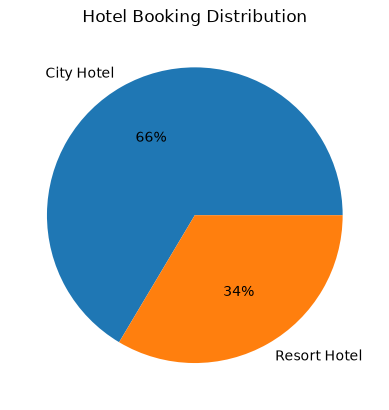

In [ ]:
hotel_counts=df["hotel"].value_counts()
plt.pie(hotel_counts,labels=hotel_counts.index,autopct="%1.0f%%")
plt.title("Hotel Booking Distribution")
plt.show()
#City hotels account for 66% of the bookings, indicate that the data is more focused on "urban travellers".

##### **2. Class balance: Cancellation**

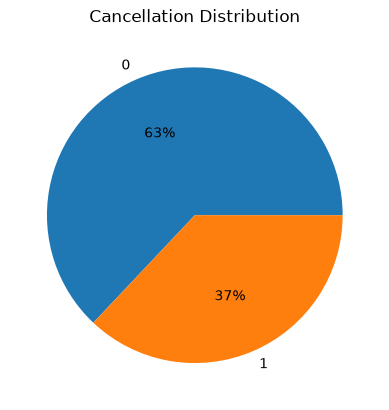

In [ ]:
cancellation_count=df["is_canceled"].value_counts()
plt.pie(cancellation_count,labels=cancellation_count.index,autopct="%1.0f%%")
plt.title("Cancellation Distribution")
plt.show()
#0: not canceled, 1: canceled

**Insight:** 37% of the bookings are cancelled, representing a substantial revenue risk for the hotel.

##### **3. LEAD TIME**

<Axes: xlabel='lead_time'>

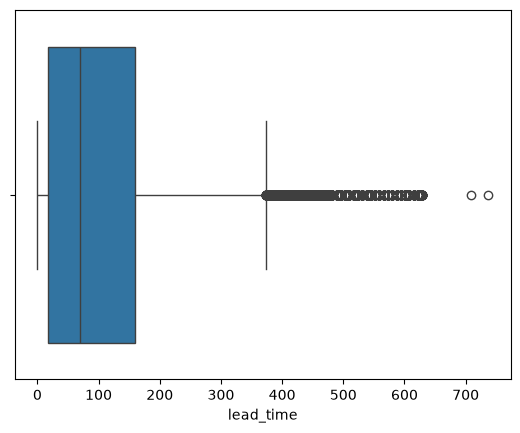

In [ ]:
sns.boxplot(x=df["lead_time"])

**Insight:** 
The boxplot shows that the lead_time (the duration between the booking date and the arrival date) is very right-skewed.
- The median is around 70-80 days (the line): Typical customers book 70-80 days in advanced
- The blue box ranges from 30 to 160 days: The majority of customers book 30-160 days in advanced
-->The lead_time varies a lot

- Numerous right-skewed outliers exist: a small number of people book exceptionally early, more than a year in advanced, creating the right-skewed distribution (median != mean)

##### **4. Booking Season**

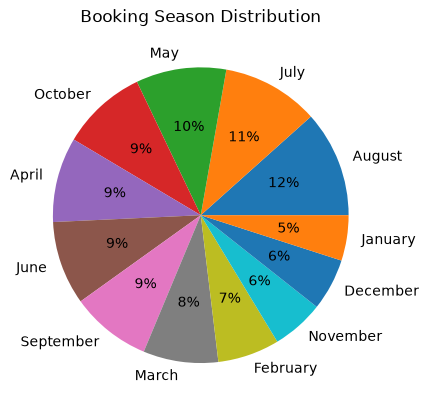

In [ ]:
month_arrived=df["arrival_date_month"].value_counts()
plt.pie(month_arrived,labels=month_arrived.index,autopct="%1.0f%%")
plt.title("Booking Season Distribution")
plt.show()

**Insight:** August and July has the highest booking volume, suggesting strong summer seasonality

##### **5. Booking Channel**

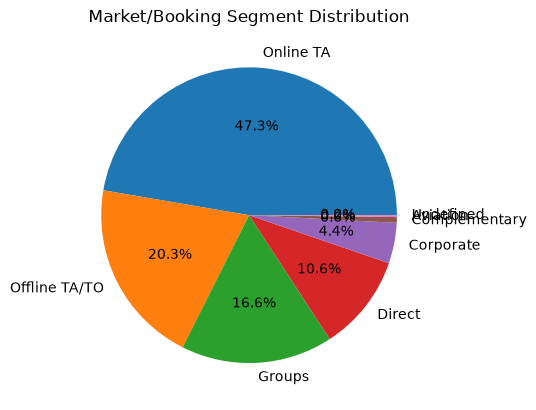

In [ ]:
market_segment=df["market_segment"].value_counts()
plt.pie(market_segment,labels=market_segment.index,autopct="%1.1f%%")
plt.title("Market/Booking Segment Distribution")
plt.show()

**Insight:** Online Travel Agent holds the largest share, indicating that the majority of customer chooses online travel agency (Traveloka, Booking.com,...) to book their vacations, following by offline TA. 

##### **6. Customer type**

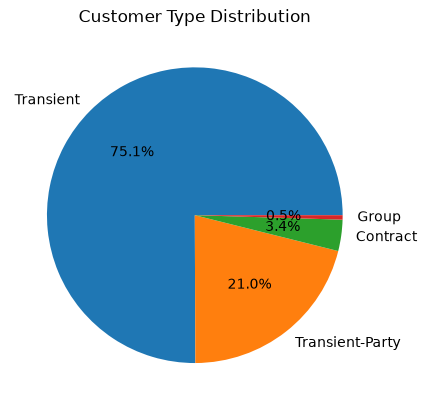

In [ ]:
customer_type=df["customer_type"].value_counts()
plt.pie(customer_type,labels=customer_type.index,autopct="%1.1f%%")
plt.title("Customer Type Distribution")
plt.show()

Transient customer is the group that hotels serves the most.

##### **7. Deposit type**

<Axes: xlabel='deposit_type', ylabel='count'>

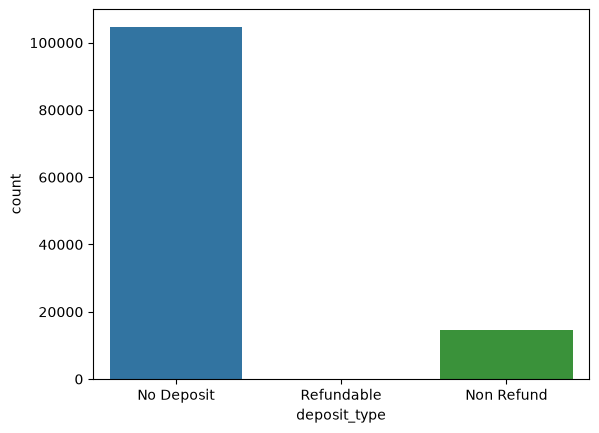

In [ ]:
sns.countplot(df,x="deposit_type",hue="deposit_type")

No deposit type is used the most by hotels. But would it suggest that this policy will create losses for hotels?

##### **8. Customer loyalty**

In [ ]:
df["is_repeated_guest"].value_counts()

is_repeated_guest
0    115580
1      3810
Name: count, dtype: int64

In [25]:
df["previous_cancellations"].value_counts()

previous_cancellations
0     112906
1       6051
2        116
3         65
24        48
11        35
4         31
26        26
25        25
6         22
19        19
5         19
14        14
13        12
21         1
Name: count, dtype: int64

**Insight:** Suggests that most guests have no prior cancellations. However, small subset shows REPEATED behavior of cancellation.

**Insight:** The result suggest limited customer retention, most bookings are made by first-time customer. It might suggest that most of the hotels surveyed aren't luxury hotels (correlate with income elasticity of customers)

#### **BIVARIATE ANALYSIS**

##### **1. Lead time and Cancellation**

<Axes: xlabel='is_canceled', ylabel='lead_time'>

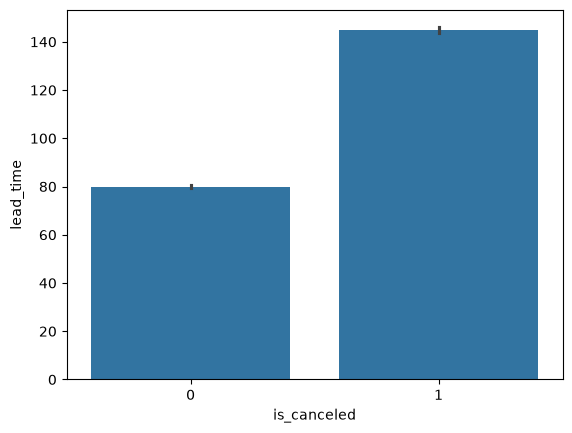

In [26]:
sns.barplot(
    y='lead_time',
    x='is_canceled',
    data=df
)

**Insight:** The plot shows that customers who book in advanced from 80 - 140 days usually cancel their booking. A hypothesis accounts for the phenomenon might be unexpected events occuring on the check-in day after the booking.
One factor might lead to cancellation: longer lead time

##### **2. Deposit type and Cancellation**

In [27]:
pd.crosstab(
    df['deposit_type'],
    df['is_canceled'],
    normalize='index'
).rename(columns={"0":"Not Canceled","1":"Canceled"})

is_canceled,Not Canceled,Canceled
deposit_type,,
No Deposit,0.716230,0.283770
Non Refund,0.006376,0.993624
Refundable,0.777778,0.222222


**Insight:** 
- Customers completing the booking with non-refund deposit type are strongly correlated with cancellation, which gives a worht-looking insight because those customers will lose money when they cancel. (0.99)
- While for "No Deposit" and "Refundable" deposit types, customers are less likely to cancel the booking
--> Why are there this contradiction to the common situation? Might it be that the cancellation of non-refund customers type is held mainly in a large-scale booking? It will be further discover in the multivariate analysis

In [66]:
#Rename the the is_canceled column values to more descriptive names
df["is_canceled"]=df["is_canceled"].replace({"0": "Not Canceled", "1": "Canceled"})
df["is_canceled"]

0         Not Canceled
1         Not Canceled
2         Not Canceled
3         Not Canceled
4         Not Canceled
              ...     
119385    Not Canceled
119386    Not Canceled
119387    Not Canceled
119388    Not Canceled
119389    Not Canceled
Name: is_canceled, Length: 119390, dtype: str

##### **3. Market Segment and Cancellation**

<Axes: xlabel='market_segment', ylabel='count'>

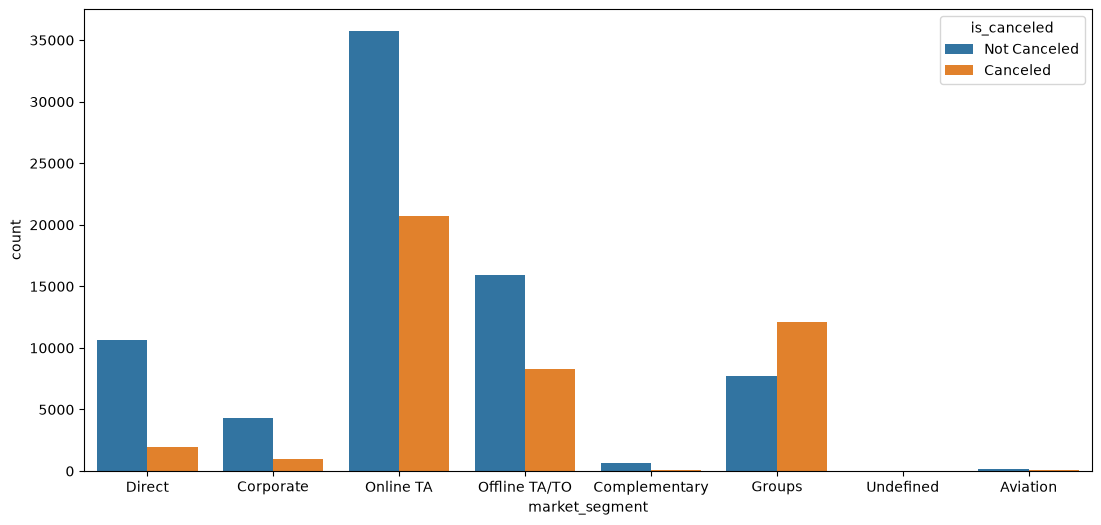

In [67]:
plt.figure(figsize=(13,6))
sns.countplot(x="market_segment",hue="is_canceled",data=df)

In [68]:
pd.crosstab(df["market_segment"],df["is_canceled"],normalize="index")

is_canceled,Canceled,Not Canceled
market_segment,,
Aviation,0.219409,0.780591
Complementary,0.130552,0.869448
Corporate,0.187347,0.812653
Direct,0.153419,0.846581
Groups,0.610620,0.389380
Offline TA/TO,0.343160,0.656840
Online TA,0.367211,0.632789
Undefined,1.000000,0.000000


**Insight:** 
(With the help of the count graph and the correlation coefficient table, we can observe and detect more reliable correlation)
- "Groups" is the only segment that the bookings got cancelled more than it keeps. About 61% of it is cancelled. 
- Online and offline TA establish 34-36% of cancellation
- Aviation, COmplementary, Coporate and Direct segment are the most reliable, with cancellation rate of under 22%

##### **4. Arrival time of the year and Cancellation**

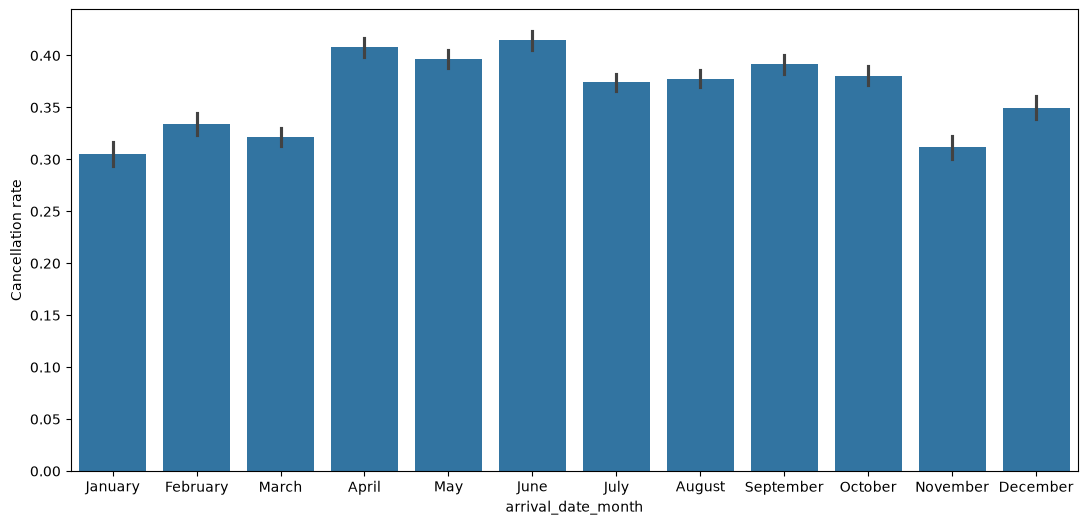

In [ ]:
#Reorder the months to be in chronological order
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
#Converting the text labels of the is_canceled column to 0/1 values for plotting cancellation rate
df_plot = df.assign(canceled=(df['is_canceled'] == 'Canceled').astype(int))

plt.figure(figsize=(13, 6))
sns.barplot(x='arrival_date_month', y='canceled', data=df_plot, order=month_order)
plt.ylabel('Cancellation rate')
plt.show()

In [80]:
pd.crosstab(df["arrival_date_month"],df["is_canceled"],values=df["lead_time"],aggfunc='mean')

is_canceled,Canceled,Not Canceled
arrival_date_month,,
April,123.551061,75.026047
August,159.308265,97.987034
December,120.425559,48.359492
February,78.294881,32.585257
January,87.888213,26.644590
July,166.493463,118.255840
June,153.257993,110.535915
March,106.174341,53.033108
May,150.396408,96.114985


**Insight:** 
- April, May, Jun (and maybe September) - spring and early summer establish the highest cancellation rate of 39-41%, while the rest of summer to autumn remains in 37-39% of cancellation.  
- January, March, November - winter and early spring shows lowest rate of cancellation

- This indicates a seasonal pattern for cancellation. Lead time can be closely related to seasonal pattern for cancellation  

##### **CONCLUSION:**
- In overall, there are several factors that can contribute to cancellation:
  A longer lead time of around 3-4 months,
  Non-Refund-deposit-type bookings, 
  "Groups" and "TA" booking segment,
  Late spring - Early summer arrival date
  
- Specifically, some results from bivariate analysis has gave rise to some hypothesis about the link among these variables that we will test in the multivariate analysis. That is namely the link among: market segments - deposit type - cancellation; seasonal cancellation pattern - lead time (-hotel type); arrival date - market segment - cancellation

#### **MULTIVARIATE ANALYSIS**

##### **1. The link among deposit_type, market_segment or customer_type and cancellation**

One quick note that the "Group" customer_type differs from the "Groups" market_segment (for example, a tour operator or agency block-books rooms in the Groups segment, but each room is recorded as an individual or small-party stay.) 

In [ ]:
pd.crosstab(df_org['market_segment'], df_org['customer_type'])

customer_type,Contract,Group,Transient,Transient-Party
market_segment,,,,
Aviation,0,2,218,17
Complementary,2,6,703,32
Corporate,22,29,3576,1668
Direct,14,134,11336,1122
Groups,735,16,8427,10633
Offline TA/TO,1817,211,14054,8137
Online TA,1486,179,51299,3513
Undefined,0,0,0,2


<Axes: xlabel='deposit_type', ylabel='market_segment'>

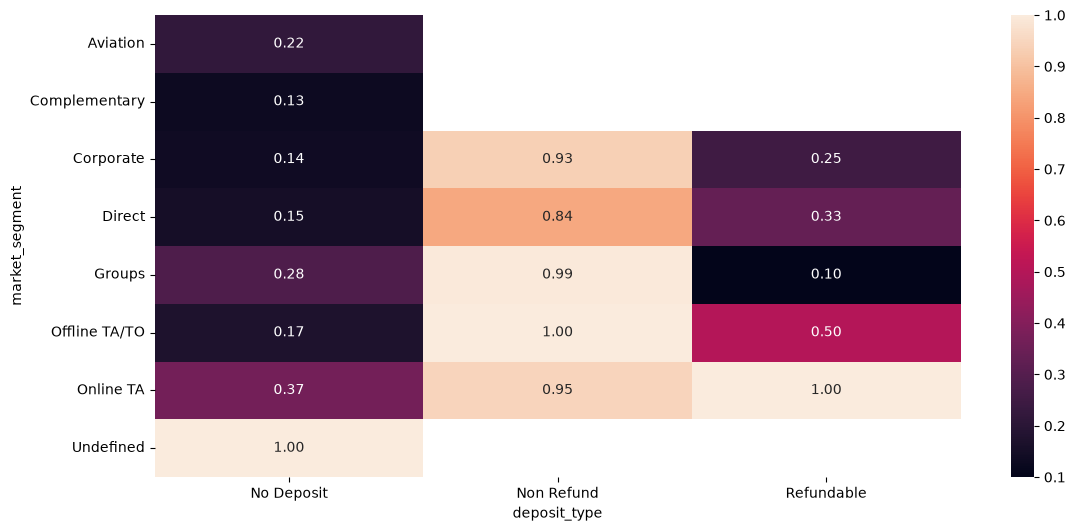

In [93]:
plt.figure(figsize=(13,6))
df_plot=df.assign(canceled=(df["is_canceled"]=="Canceled").astype(int))
rate=pd.crosstab(df_plot["market_segment"],
                 df_plot["deposit_type"],     #assign rows and columns
                 values=df_plot["canceled"],  #what to calculate in the cell: here is the cancellation rate
                 aggfunc="mean")              #calculate the mean of all cancellation for one type
sns.heatmap(rate,fmt='.2f',annot=True)

**Insight:** As it is shown in the heatmap, the "Groups" booking segment with "Non Refund" deposite types exhibits strongest correlation with cancellation. Besides, the "Coporate" (93.4%), "Offline TA" (99.9%) and "Online TA" (94.6%) also exhibit similiar trend. Noticeably, online TA with "Refundable" deposit type exhibit perfect positive correlation with cancellation, this seems suspicious so let's check the group size.

In [94]:
pd.crosstab(df_org['market_segment'], df_org['deposit_type'], margins=True)

deposit_type,No Deposit,Non Refund,Refundable,All
market_segment,,,,
Aviation,237,0,0,237
Complementary,743,0,0,743
Corporate,4957,334,4,5295
Direct,12581,19,6,12606
Groups,10509,9172,130,19811
Offline TA/TO,19209,5006,4,24219
Online TA,56403,56,18,56477
Undefined,2,0,0,2
All,104641,14587,162,119390


**Insight:** The customer group that book through "Online TA" and has a "Refundable" deposit type is extremely small compared to other elements in the table, so (n = 18 out of 119,390 bookings), so its 100% cancellation rate is not statistically reliable and should not be interpreted as a meaningful pattern.

##### **2. The link among arrival date, lead time and cancellation (+ hotel)**

In [ ]:
#For cancellation rate
df_plot = df.assign(canceled=(df['is_canceled'] == 'Canceled').astype(int))

month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
#Calculate several statistics at once by using agg.
summary = (df_plot.groupby(['arrival_date_month','hotel'])
                  .agg(cancel_rate=('canceled', 'mean'),
                       avg_lead_time=('lead_time', 'mean'),
                       median_lead_time=('lead_time', 'median'), #median lead time is a better measure of central tendency for skewed data
                       n=('canceled', 'size'))
               .unstack('hotel')
                  .reindex(month_order))

summary

cancel_rate              avg_lead_time               \
hotel               City Hotel Resort Hotel    City Hotel Resort Hotel   
arrival_date_month                                                       
January               0.396681     0.148199     56.611884    26.056088   
February              0.382880     0.256204     52.815307    39.930068   
March                 0.369464     0.228717     73.162744    64.227518   
April                 0.463235     0.293433     99.119519    85.917706   
May                   0.443756     0.287721    116.174441   121.050295   
June                  0.446922     0.330706    124.346972   138.358621   
July                  0.408754     0.314017    153.589639   105.783293   
August                0.400980     0.334491    130.749527   103.495096   
September             0.420270     0.323681    127.835000   157.723295   
October               0.429717     0.275105    125.853254   116.879325   
November              0.381226     0.189167     94.022493    45.397620   
December              0.421104     0.238293     84.767183    56.075529   

                   median_lead_time                       n               
hotel                    City Hotel Resort Hotel City Hotel Resort Hotel  
arrival_date_month                                                        
January                        32.0          5.0       3736         2193  
February                       30.0         17.0       4965         3103  
March                          51.0         30.5       6458         3336  
April                          87.0         65.0       7480         3609  
May                            99.0        102.0       8232         3559  
June                          113.0        133.0       7894         3045  
July                          141.0         93.0       8088         4573  
August                        117.0         81.0       8983         4894  
September                      72.0        167.0       7400         3108  
October                        76.0         69.0       7605         3555  
November                       51.0         24.0       4357         2437  
December                       40.0         31.0       4132         2648

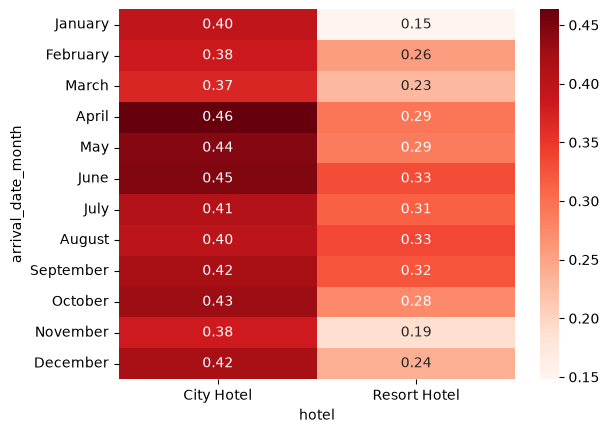

In [98]:
sns.heatmap(summary['cancel_rate'], annot=True, fmt='.2f', cmap='Reds')
plt.show()

<Axes: xlabel='hotel', ylabel='arrival_date_month'>

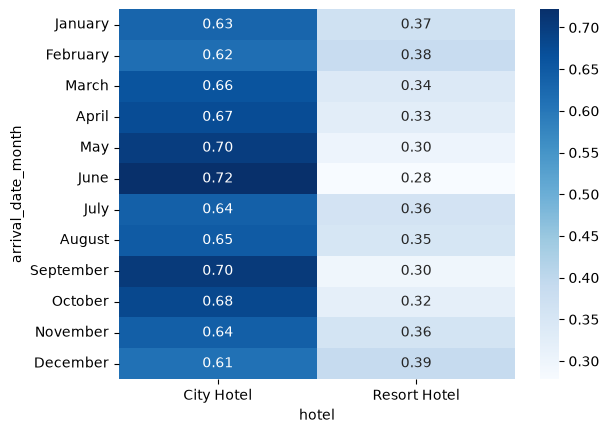

In [102]:
#Double check if the peak for two hotel types can be reason through cancellation rate of each month from the above chart.
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
date_hotel=pd.crosstab(df["arrival_date_month"],df["hotel"],normalize="index")
date_hotel=date_hotel.reindex(month_order)
sns.heatmap(date_hotel,annot=True,fmt='.2f',cmap='Blues')

**Insight:** 
- City Hotel cancels more than Resort Hotel in every month. The City column is darker all the way down (0.37 to 0.46), while Resort ranges from 0.15 to 0.33. The gap is largest in January (0.40 vs 0.15) and November (0.38 vs 0.19).

- City Hotels and Resort Hotels have peaks in different time stamps: City Hotels' bookings and cancellation peaks from April to June (although throughout the year it is relatively the same), while Resort Hotels booking peaks in July - August,Nov - Dec and Jan - Feb with cancellation peaks from Jun - September.

- City Hotels and Resort Hotels have different cancellation range as well: For City Hotels the range is 9 points (March and April). For Resort Hotels the range is 18 points (January and June)

--> Resort Hotels indicate more seasonality.

- Regarding lead time, the majority of cancellations not regarding of hotel types recorded lead time of around 3-4 months (still the same pattern for bivariate analysis)

## **CONCLUSION:**
- Market segment shows the largest, most interpretable gap. Group bookings are cancelled about 4 times as often as Direct bookings (61% vs 15%). Long lead time is the strongest general warning sign. Deposit type has the highest single rate (Non Refund, 99.4%). 
- Groups booking segment and Non Refund deposit type establish highest correlation rate with cancellation.
- Seasonality does not exhibit strong correlation to cancellation (<50%>), but it has been shown that seasonality also differs for types of hotels (Resort > City)
- Notably, the correlation between Non Refund deposit type and cancellation is a surprising result, counter-intuitive and also contrary to the intitial hypothesis (Guests who pay a non-refundable deposit cancel less, because they would lose money.)